# 08 · Model 4 — PyTorch Recurrent Neural Network (LSTM)

**Idea:** An aircraft engine's health degradation is an evolving time-series trajectory. Rather than summarizing the past cycles with static summary statistics (like rolling averages or slopes), a **Long Short-Term Memory (LSTM)** network processes the sequential 30-cycle sensor window step-by-step.

Its internal gating mechanism (forget gate, input gate, cell state, and output gate) allows the network to remember long-term baseline trends and capture the exact moment degradation accelerates.

In [1]:
import os
os.environ.setdefault('MPLCONFIGDIR', '/tmp/matplotlib_cache')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

from utils import (
    SEED, RUL_CAP, evaluate, compute_nasa_score, stage_table,
    plot_validation, plot_test, savefig,
    PROCESSED_DATA, MODELS, RESULTS
)

torch.manual_seed(SEED)
np.random.seed(SEED)
device = torch.device('cpu')
print('Using device:', device)

Using device: cpu


## 1. Load Preprocessed Sequence Tensors

We load the 3D sequence arrays generated in Notebook 07 and wrap them into PyTorch `DataLoader` objects.

In [2]:
X_train = np.load(PROCESSED_DATA / 'X_train_seq.npy')
y_train = np.load(PROCESSED_DATA / 'y_train_seq.npy')
y_raw_train = np.load(PROCESSED_DATA / 'y_raw_train_seq.npy')
u_train = np.load(PROCESSED_DATA / 'u_train_seq.npy')

X_val = np.load(PROCESSED_DATA / 'X_val_seq.npy')
y_val = np.load(PROCESSED_DATA / 'y_val_seq.npy')
y_raw_val = np.load(PROCESSED_DATA / 'y_raw_val_seq.npy')
u_val = np.load(PROCESSED_DATA / 'u_val_seq.npy')

X_test = np.load(PROCESSED_DATA / 'X_test_seq.npy')
y_test = np.load(PROCESSED_DATA / 'y_test_seq.npy')
y_raw_test = np.load(PROCESSED_DATA / 'y_raw_test_seq.npy')

train_loader = DataLoader(
    TensorDataset(torch.from_numpy(X_train), torch.from_numpy(y_train)),
    batch_size=64, shuffle=True
)
val_loader = DataLoader(
    TensorDataset(torch.from_numpy(X_val), torch.from_numpy(y_val)),
    batch_size=128, shuffle=False
)

print(f'Train batches: {len(train_loader)} (total samples: {len(X_train):,})')
print(f'Val batches:   {len(val_loader)} (total samples: {len(X_val):,})')
print(f'Test samples:  {len(X_test)}')

Train batches: 223 (total samples: 14,241)
Val batches:   28 (total samples: 3,490)
Test samples:  100


## 2. Define the PyTorch LSTM Regressor

Architecture:
- Input shape: `(batch_size, 30, 14)`
- 2-layer stacked LSTM with 64 hidden units and recurrent dropout (0.2)
- Extraction of final time-step hidden representation $h_T$
- Multi-Layer Perceptron (MLP) regression head: `Linear(64, 32)` $\rightarrow$ `ReLU` $\rightarrow$ `Dropout(0.2)` $\rightarrow$ `Linear(32, 1)`

In [3]:
class LSTMRegressor(nn.Module):
    def __init__(self, input_dim=14, hidden_dim=64, num_layers=2, dropout=0.2):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=input_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0.0
        )
        self.fc = nn.Sequential(
            nn.Linear(hidden_dim, 32),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(32, 1)
        )

    def forward(self, x):
        out, _ = self.lstm(x)
        last_hidden = out[:, -1, :]  # Final hidden state across sequence
        return self.fc(last_hidden).squeeze(-1)

model = LSTMRegressor(input_dim=14, hidden_dim=64, num_layers=2, dropout=0.2).to(device)
print(model)
num_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Total trainable parameters: {num_params:,}')

LSTMRegressor(
  (lstm): LSTM(14, 64, num_layers=2, batch_first=True, dropout=0.2)
  (fc): Sequential(
    (0): Linear(in_features=64, out_features=32, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=32, out_features=1, bias=True)
  )
)
Total trainable parameters: 55,873


## 3. Train the Model with Early Stopping & LR Scheduling

We use **Huber Loss (`SmoothL1Loss`)** because it behaves quadratically for small errors and linearly for large errors, making optimization stable against sensor noise and spikes.

We use **AdamW** with a learning rate scheduler that halves the learning rate when validation loss plateaus.

In [4]:
criterion = nn.SmoothL1Loss()
optimizer = torch.optim.AdamW(model.parameters(), lr=0.002, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=3)

train_losses, val_losses = [], []
best_val_loss = float('inf')
best_weights = None
patience = 8
patience_counter = 0

print('Starting LSTM training...')
for epoch in range(1, 35):
    # Training phase
    model.train()
    running_train_loss = 0.0
    for bx, by in train_loader:
        bx, by = bx.to(device), by.to(device)
        optimizer.zero_grad()
        preds = model(bx)
        loss = criterion(preds, by)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        running_train_loss += loss.item() * len(by)
    train_loss = running_train_loss / len(train_loader.dataset)
    train_losses.append(train_loss)

    # Validation phase
    model.eval()
    running_val_loss = 0.0
    with torch.no_grad():
        for bx, by in val_loader:
            bx, by = bx.to(device), by.to(device)
            preds = model(bx)
            loss = criterion(preds, by)
            running_val_loss += loss.item() * len(by)
    val_loss = running_val_loss / len(val_loader.dataset)
    val_losses.append(val_loss)

    scheduler.step(val_loss)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_weights = model.state_dict().copy()
        patience_counter = 0
    else:
        patience_counter += 1
        if patience_counter >= patience:
            print(f'Early stopping triggered at epoch {epoch}')
            break

    if epoch % 5 == 0 or epoch == 1:
        print(f'Epoch {epoch:2d}/35 | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | LR: {optimizer.param_groups[0]["lr"]:.6f}')

model.load_state_dict(best_weights)
torch.save(model.state_dict(), MODELS / 'lstm_model.pt')
print('Best LSTM weights saved to outputs/models/lstm_model.pt')

Starting LSTM training...
Epoch  1/35 | Train Loss: 55.3605 | Val Loss: 36.3091 | LR: 0.002000
Epoch  5/35 | Train Loss: 14.7061 | Val Loss: 10.5296 | LR: 0.002000
Epoch 10/35 | Train Loss: 13.8981 | Val Loss: 10.6338 | LR: 0.001000
Early stopping triggered at epoch 12
Best LSTM weights saved to outputs/models/lstm_model.pt


## 4. Training Loss Curve

Let's plot the training and validation loss progression across epochs to monitor convergence.

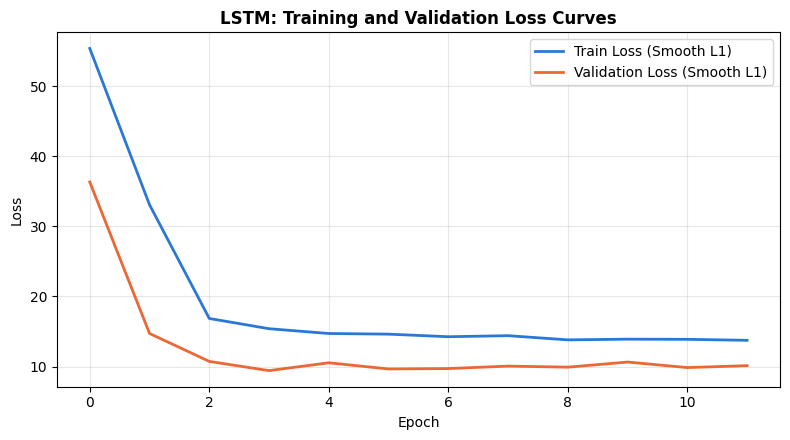

In [5]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(train_losses, label='Train Loss (Smooth L1)', color='#2a78d6', lw=2)
ax.plot(val_losses, label='Validation Loss (Smooth L1)', color='#eb6834', lw=2)
ax.set_title('LSTM: Training and Validation Loss Curves', fontsize=12, fontweight='bold')
ax.set_xlabel('Epoch')
ax.set_ylabel('Loss')
ax.legend()
ax.grid(True, alpha=0.3)
savefig('08_lstm_training_loss')

## 5. Validation Set Performance & Early vs Late Life Analysis

We evaluate the trained LSTM on all cycles of the 20 validation engines.

In [6]:
model.eval()
with torch.no_grad():
    val_preds = model(torch.from_numpy(X_val).to(device)).cpu().numpy()

val_metrics = evaluate(y_val, val_preds)
print('LSTM Validation Metrics:', val_metrics)

# Save validation predictions
val_df_out = pd.DataFrame({'unit': u_val, 'RUL': y_val, 'predicted': val_preds, 'RUL_raw': y_raw_val})
val_df_out.to_csv(RESULTS / 'lstm_val_predictions.csv', index=False)

# Early vs Late degradation breakdown
st_table = stage_table(y_raw_val, y_val, val_preds)
print('\nEarly vs Late Life Performance (Validation):')
print(st_table)

LSTM Validation Metrics: {'RMSE': 13.6, 'MAE': 10.61, 'R2': 0.894}

Early vs Late Life Performance (Validation):
                   Rows   RMSE    MAE
Stage                                
early (RUL > 100)  1470  15.44  13.32
late (RUL ≤ 100)   2020  12.08   8.63


### Validation Diagnostics Plot

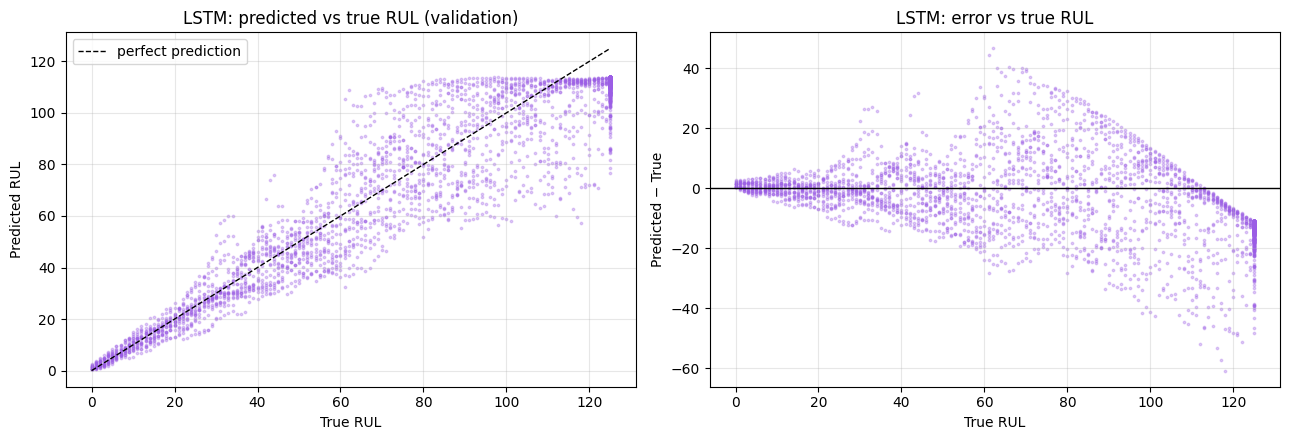

In [7]:
plot_validation('LSTM', y_val, val_preds, '08_lstm_val_diagnostic')

## 6. Official NASA Test Set Performance (100 Engines)

Each of the 100 test engines is predicted using its **final 30-cycle sequence window**.

LSTM Official Test Set Results:
  Test RMSE:   13.23 cycles
  Test MAE:    9.88 cycles
  Test R²:     0.891
  NASA Score:  240.50


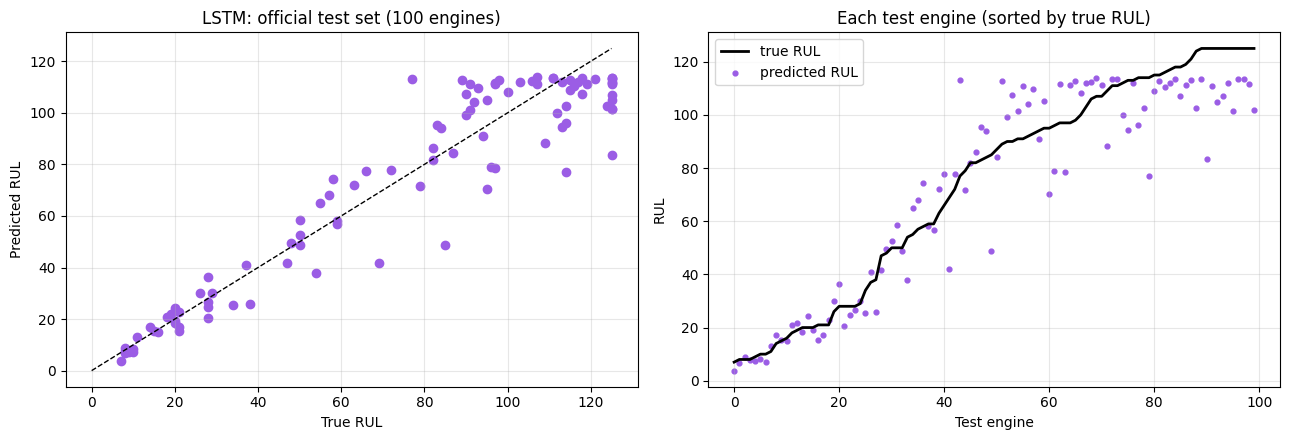

In [8]:
with torch.no_grad():
    test_preds = model(torch.from_numpy(X_test).to(device)).cpu().numpy()

test_metrics = evaluate(y_test, test_preds)
test_nasa_score = compute_nasa_score(y_test, test_preds)

print('LSTM Official Test Set Results:')
print(f'  Test RMSE:   {test_metrics["RMSE"]} cycles')
print(f'  Test MAE:    {test_metrics["MAE"]} cycles')
print(f'  Test R²:     {test_metrics["R2"]}')
print(f'  NASA Score:  {test_nasa_score:.2f}')

# Save test predictions
test_df_out = pd.DataFrame({'unit': range(1, 101), 'RUL': y_test, 'predicted': test_preds, 'RUL_raw': y_raw_test})
test_df_out.to_csv(RESULTS / 'lstm_test_predictions.csv', index=False)

plot_test('LSTM', y_test, test_preds, '08_lstm_test_scatter')